<a href="https://colab.research.google.com/github/dldklv/NN-DL/blob/main/6th%20exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# MNIST datasetini yuklash
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Dataset muvaffaqiyatli yuklandi!")
print("Training data:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing data:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset muvaffaqiyatli yuklandi!
Training data: (60000, 28, 28)
Training labels: (60000,)
Testing data: (10000, 28, 28)
Testing labels: (10000,)


MNIST dataset yuklanmoqda...
Training: (60000, 28, 28)
Testing: (10000, 28, 28)


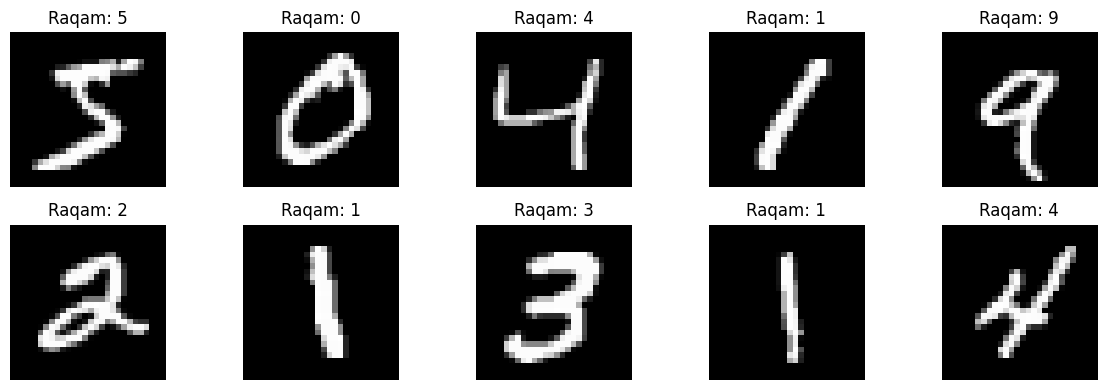


RELU ACTIVATION


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8745 - loss: 0.4275 - val_accuracy: 0.9417 - val_loss: 0.1965
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9446 - loss: 0.1851 - val_accuracy: 0.9624 - val_loss: 0.1273
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9589 - loss: 0.1352 - val_accuracy: 0.9657 - val_loss: 0.1117
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9666 - loss: 0.1093 - val_accuracy: 0.9712 - val_loss: 0.0976
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9729 - loss: 0.0912 - val_accuracy: 0.9728 - val_loss: 0.0883
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9746 - loss: 0.0798 - val_accuracy: 0.9746 - val_loss: 0.0837
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9781 - loss: 0.0686 - val_accuracy: 0.9758 - val_loss: 0.0821
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9798 - loss: 0.0626 - val_accuracy: 0.

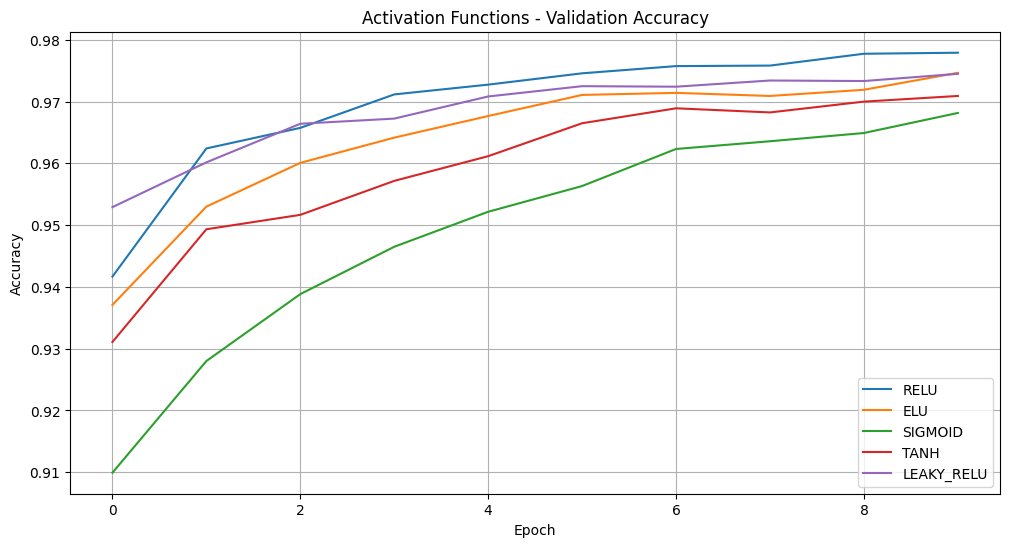

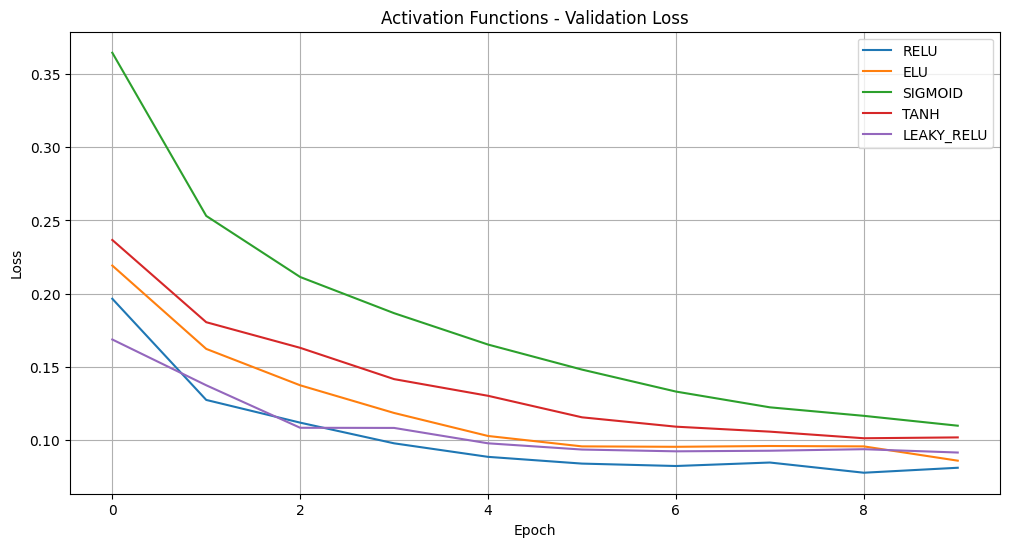

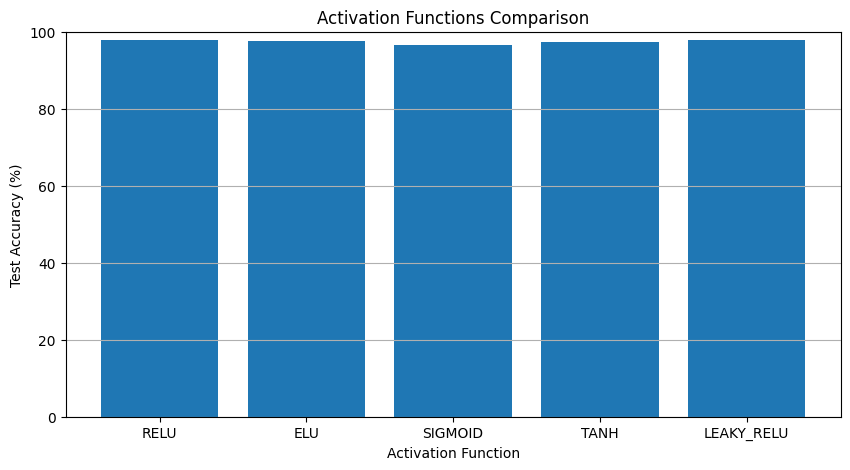


ENG YAXSHI NATIJA:
Activation: LEAKY_RELU
Accuracy: 97.85%


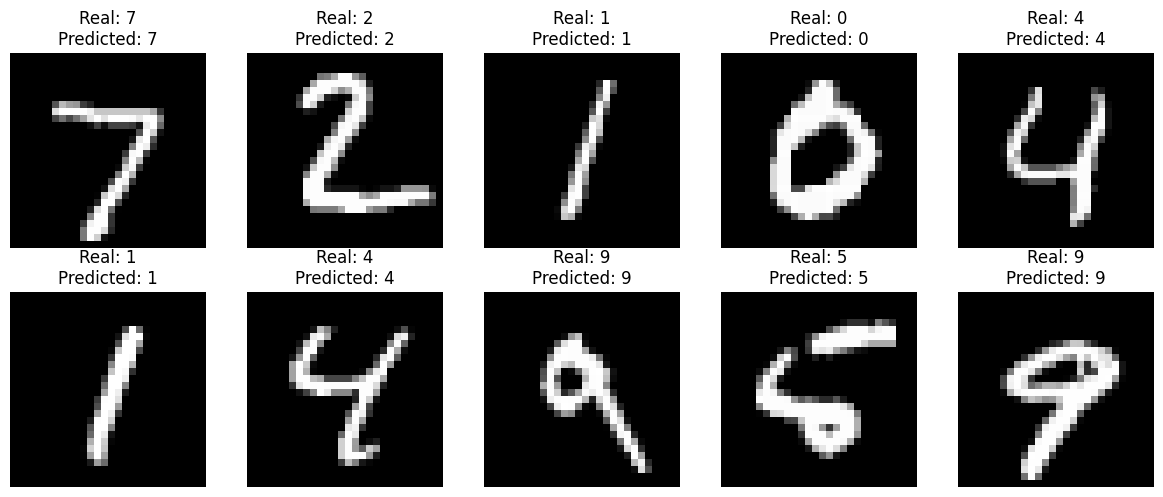


DASTUR MUVAFFAQIYATLI YAKUNLANDI!


In [2]:

# ==========================================
# MNIST DATASET - NEURAL NETWORK
# ACTIVATION FUNCTIONS COMPARISON
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Flatten, Dropout, LeakyReLU
)
from tensorflow.keras.datasets import mnist

# 1. DATASETNI YUKLASH
print("MNIST dataset yuklanmoqda...")

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. MA'LUMOTLARNI NORMALIZATSIYA QILISH
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Training:", x_train.shape)
print("Testing:", x_test.shape)

# 3. DATASETDAN NAMUNALAR
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Raqam: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()


# 4. AKTIVATSIYA FUNKSIYALARI
activations = ['relu', 'elu', 'sigmoid', 'tanh', 'leaky_relu']


# 5. MODEL YARATISH FUNKSIYASI
def create_model(activation):

    model = Sequential()

    model.add(Flatten(input_shape=(28, 28)))

    if activation == 'leaky_relu':

        model.add(Dense(128))
        model.add(LeakyReLU(negative_slope=0.01))

        model.add(Dense(64))
        model.add(LeakyReLU(negative_slope=0.01))

    else:

        model.add(Dense(128, activation=activation))
        model.add(Dropout(0.2))

        model.add(Dense(64, activation=activation))

    # Chiqish qatlami
    # Softmax 10 ta raqam ehtimolini hisoblaydi
    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# 6. MODELLARNI O'QITISH
results = []
histories = {}
models = {}

EPOCHS = 10
BATCH_SIZE = 128

for activation in activations:

    print("\n" + "=" * 50)
    print(f"{activation.upper()} ACTIVATION")
    print("=" * 50)

    model = create_model(activation)

    history = model.fit(
        x_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.2,
        verbose=1
    )

    # Test qilish
    test_loss, test_accuracy = model.evaluate(
        x_test, y_test, verbose=0
    )

    print(f"\nTest Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

    results.append({
        'Activation': activation.upper(),
        'Test Accuracy': test_accuracy * 100,
        'Test Loss': test_loss
    })

    histories[activation] = history.history
    models[activation] = model


# 7. NATIJALARNI JADVALDA KO'RSATISH
results_df = pd.DataFrame(results)

print("\nAKTIVATSIYA FUNKSIYALARI NATIJALARI:")
print(results_df.to_string(index=False))


# 8. ACCURACY TAQQOSLASH
plt.figure(figsize=(12, 6))

for activation in activations:
    plt.plot(
        histories[activation]['val_accuracy'],
        label=activation.upper()
    )

plt.title('Activation Functions - Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()


# 9. LOSS TAQQOSLASH
plt.figure(figsize=(12, 6))

for activation in activations:
    plt.plot(
        histories[activation]['val_loss'],
        label=activation.upper()
    )

plt.title('Activation Functions - Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()


# 10. TEST ACCURACY DIAGRAMMASI
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Activation'],
    results_df['Test Accuracy']
)

plt.title('Activation Functions Comparison')
plt.xlabel('Activation Function')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()


# 11. ENG YAXSHI MODEL
best_index = results_df['Test Accuracy'].idxmax()
best_activation = results_df.loc[best_index, 'Activation'].lower()

print("\nENG YAXSHI NATIJA:")
print("Activation:", best_activation.upper())
print(
    "Accuracy:",
    f"{results_df.loc[best_index, 'Test Accuracy']:.2f}%"
)


# 12. MODEL ORQALI RAQAMNI ANIQLASH
best_model = models[best_activation]

predictions = best_model.predict(x_test[:10], verbose=0)

plt.figure(figsize=(12, 5))

for i in range(10):

    predicted_digit = np.argmax(predictions[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')

    plt.title(
        f"Real: {y_test[i]}\n"
        f"Predicted: {predicted_digit}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nDASTUR MUVAFFAQIYATLI YAKUNLANDI!")
